# Engineered feature EDA

Explore price, transaction activity, customer geography and calendar features before the next model experiment. Each row is a product and validation cutoff; the same products appear twice. The cohorts were deliberately selected and are not representative of all products.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd() if (Path.cwd()/'pyproject.toml').exists() else Path.cwd().parent
f=pd.read_csv(ROOT/'reports/generated/feature-eda.csv',dtype={'stock_code':str})
print('Rows:',len(f));display(f.head());display(f.groupby('cohort')[['log_price','log_invoice_days','uk_share','price_missing','uk_missing']].agg(['mean','min','max']))

Rows: 400


,cohort,stock_code,cutoff,log_price,log_invoice_days,uk_share,price_missing,uk_missing,next_day_bank_holiday
0,active,84077,2011-05-31,0.211320,4.736198,0.915258,0,0,0
1,active,85099B,2011-05-31,1.082283,6.150603,0.925722,0,0,0
2,active,21212,2011-05-31,0.457253,5.872118,0.675702,0,0,0
3,active,22616,2011-05-31,0.244135,4.753590,0.957534,0,0,0
4,active,15036,2011-05-31,0.569465,5.023881,0.855823,0,0,0


log_price                     log_invoice_days            \
                  mean       min       max             mean       min   
cohort                                                                  
active        0.787199  0.189072  2.596572         4.960662  2.302585   
intermittent  0.471855  0.068477  1.539015         2.343771  0.693147   

                        uk_share                price_missing          \
                   max      mean       min  max          mean min max   
cohort                                                                  
active        6.444131  0.836726  0.360636  1.0           0.0   0   0   
intermittent  3.850148  0.881211  0.076923  1.0           0.0   0   0   

             uk_missing          
                   mean min max  
cohort                           
active              0.0   0   0  
intermittent        0.0   0   0

## Distribution and missingness
Log1p transforms are applied to historical price and invoice-days. A missing 90-day history is represented by zero plus a separate missingness indicator. Invoice-days are summed daily unique-invoice counts, not guaranteed unique invoices over the full window. UK share refers to customer destination.

price_missing    0
uk_missing       0
dtype: int64

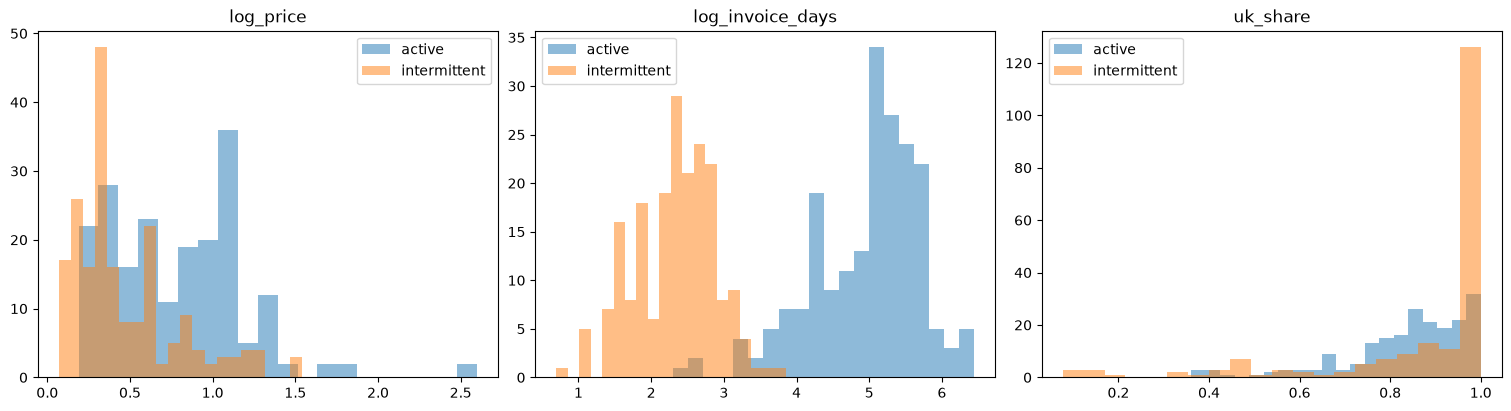

In [2]:
display(f[['price_missing','uk_missing']].sum())
fig,ax=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for group,data in f.groupby('cohort'):
 for i,column in enumerate(['log_price','log_invoice_days','uk_share']): ax[i].hist(data[column],bins=20,alpha=.5,label=group)
for i,column in enumerate(['log_price','log_invoice_days','uk_share']): ax[i].set_title(column);ax[i].legend()
plt.show()

## Interpretation
The selected snapshots have complete values, but earlier product windows or other products may not. Calendar features are deterministic and known in advance; the England-and-Wales bank holiday is a retailer-location proxy for an international customer base. Price and customer geography describe historical transactions; they do not identify causal effects, quality or manufacturing origin. Feature distributions include repeated products, and the full dataset was previously examined. Model comparisons use the later forecast windows only for validation metrics.